Dataset Shape: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

    InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/10 8:26       2.55     17850.0  United Kingdom  
1  12/1/10 8:26       3.39     17850.0  United Kingdom  
2  12/1/10 8:26       2.75     17850.0  United Kingdom  
3  12/1/10 8:26       3.39     17850.0  United Kingdom  
4  12/1/10 8:26       3.39     17850.0  United Kingdom  
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

RFM DATA

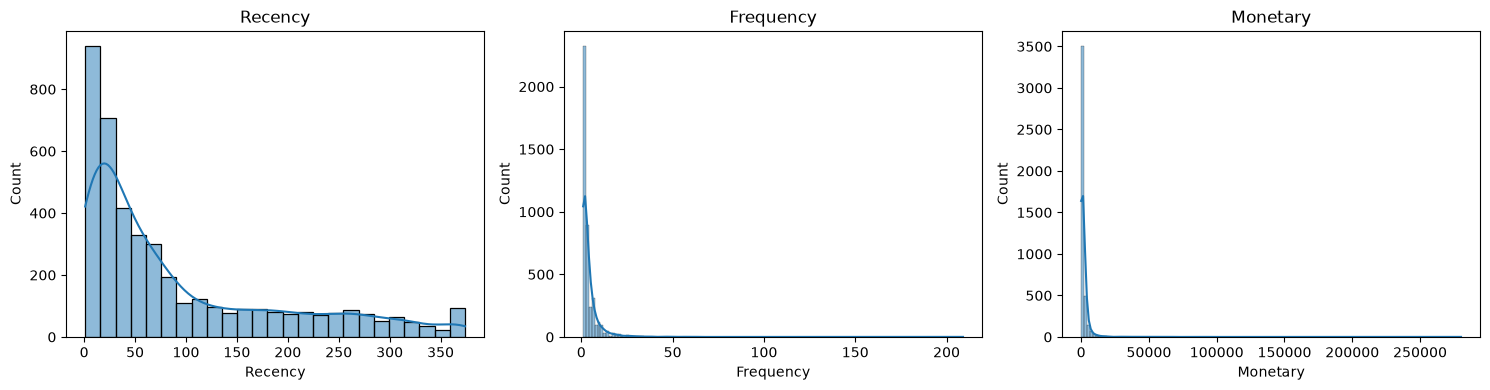

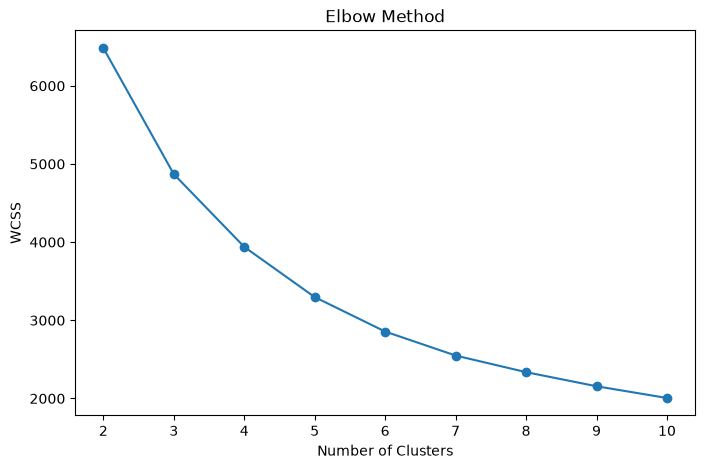


SILHOUETTE SCORES
K=2: 0.4256
K=3: 0.3284
K=4: 0.3330
K=5: 0.3180
K=6: 0.3167
K=7: 0.3099
K=8: 0.3019
K=9: 0.2779
K=10: 0.2766

KMEANS CLUSTERS
KMeans_Cluster
1    1622
3    1166
2     837
0     713
Name: count, dtype: int64


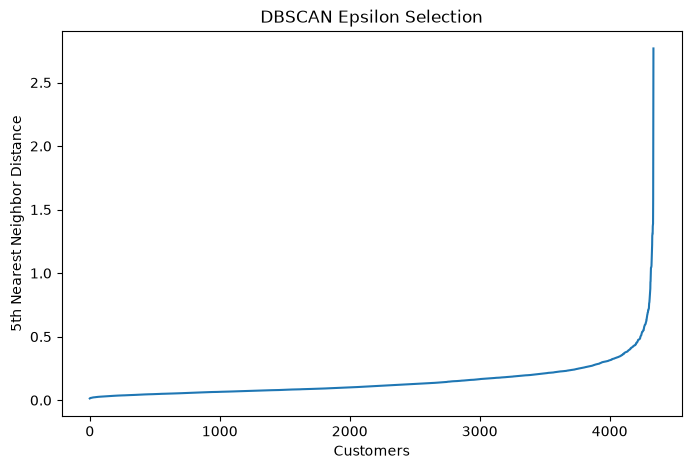


DBSCAN CLUSTERS
DBSCAN_Cluster
 0    4317
-1      21
Name: count, dtype: int64
Insufficient clusters for Silhouette Score
Noise Percentage: 0.48 %

PCA VARIANCE
[0.75078634 0.18786648]
Total Variance: 0.9386528181989527


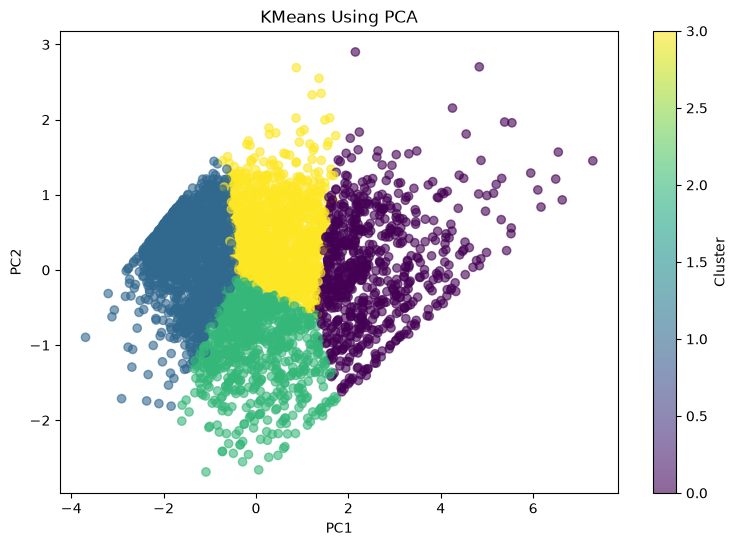

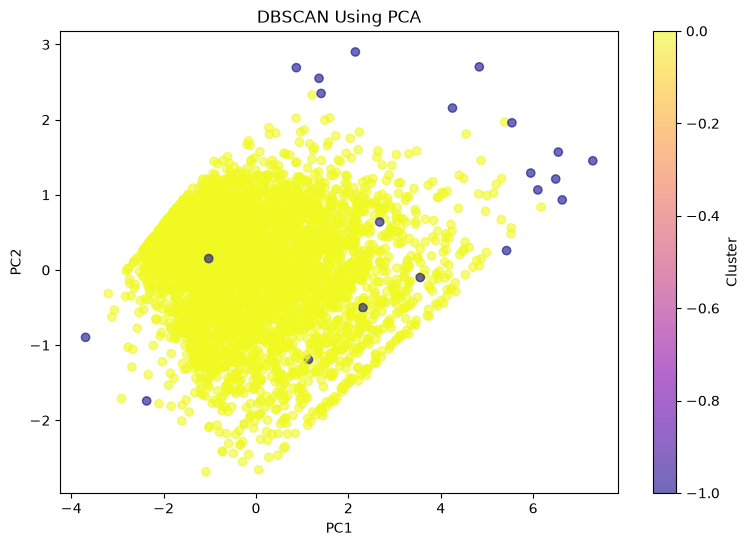

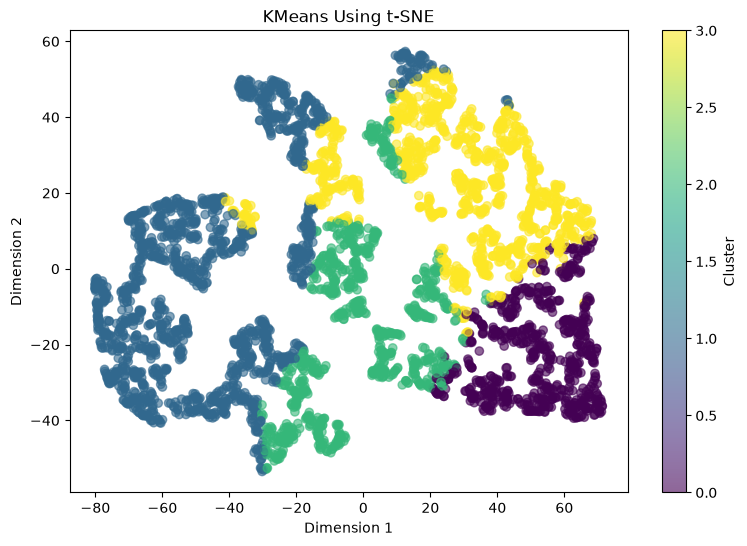

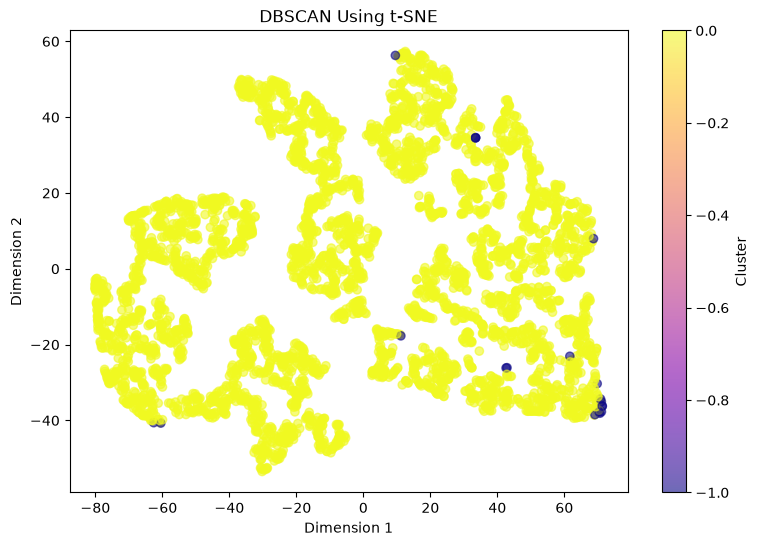


FINAL CUSTOMER PERSONAS
                Recency  Frequency  Monetary                   Persona  \
KMeans_Cluster                                                           
0                 12.17      13.75   8088.02             VIP Customers   
1                181.51       1.32    341.00  Low-Engagement Customers   
2                 17.70       2.19    557.32  Low-Engagement Customers   
3                 71.64       4.08   1801.78   At-Risk Loyal Customers   

                                      Marketing_Strategy  
KMeans_Cluster                                            
0                   Exclusive Rewards and Loyalty Points  
1                      Targeted Promotions and Reminders  
2                      Targeted Promotions and Reminders  
3               Comeback Offers and Re-engagement Emails  


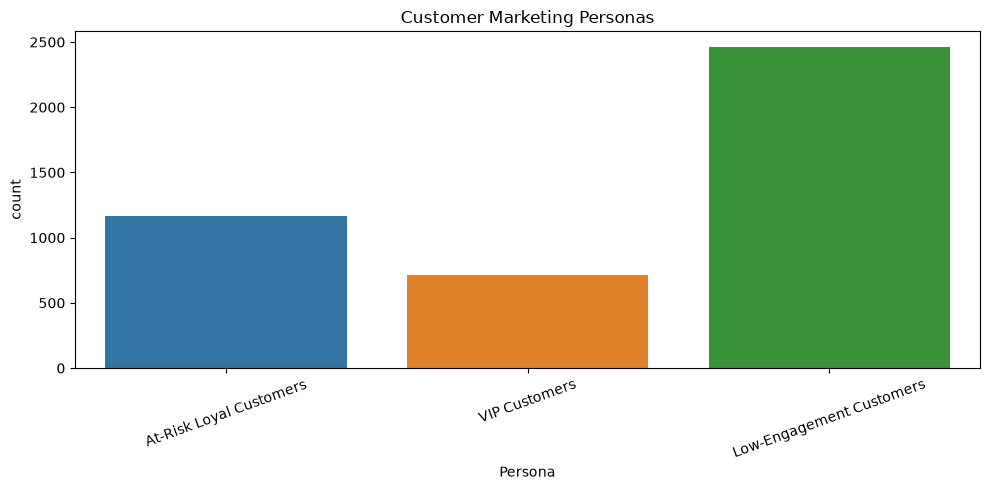


PROJECT COMPLETED SUCCESSFULLY
customer_segments.csv saved
marketing_personas.csv saved


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

df = pd.read_csv("Online_Retail.csv", encoding="ISO-8859-1")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.isnull().sum())

df = df.dropna(subset=["CustomerID"])
df = df.drop_duplicates()

df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
]

df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

print("\nRFM DATASET")
print(rfm.head())

plt.figure(figsize=(15, 4))

for i, col in enumerate(rfm.columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(rfm[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

rfm_log = np.log1p(rfm)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

wcss = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

print("\nSILHOUETTE SCORES")

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )
    print(f"K={k}: {score:.4f}")

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nKMEANS CLUSTERS")
print(rfm["KMeans_Cluster"].value_counts())

neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Customers")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("DBSCAN Epsilon Selection")
plt.show()

dbscan = DBSCAN(eps=0.8, min_samples=5)
rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("\nDBSCAN CLUSTERS")
print(rfm["DBSCAN_Cluster"].value_counts())

labels = rfm["DBSCAN_Cluster"]
non_noise = labels != -1

if labels[non_noise].nunique() >= 2:
    print(
        "DBSCAN Silhouette Score:",
        silhouette_score(
            X_scaled[non_noise],
            labels[non_noise],
            sample_size=min(2000, non_noise.sum()),
            random_state=42
        )
    )
else:
    print("Insufficient clusters for Silhouette Score")

print("Noise Percentage:", round((~non_noise).mean() * 100, 2), "%")

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nPCA VARIANCE")
print(pca.explained_variance_ratio_)
print("Total Variance:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.6
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KMeans Using PCA")
plt.colorbar(label="Cluster")
plt.show()

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm["DBSCAN_Cluster"],
    cmap="plasma",
    alpha=0.6
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DBSCAN Using PCA")
plt.colorbar(label="Cluster")
plt.show()

perplexity = min(30, len(X_scaled) - 1)

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.6
)
plt.title("KMeans Using t-SNE")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.colorbar(label="Cluster")
plt.show()

plt.figure(figsize=(9, 6))
plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=rfm["DBSCAN_Cluster"],
    cmap="plasma",
    alpha=0.6
)
plt.title("DBSCAN Using t-SNE")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.colorbar(label="Cluster")
plt.show()

cluster_profile = rfm.groupby("KMeans_Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

r_median = rfm["Recency"].median()
f_median = rfm["Frequency"].median()
m_median = rfm["Monetary"].median()

def assign_persona(row):

    if row["Recency"] <= r_median and row["Frequency"] > f_median and row["Monetary"] > m_median:
        return "VIP Customers"

    elif row["Recency"] > r_median and row["Frequency"] > f_median:
        return "At-Risk Loyal Customers"

    elif row["Recency"] <= r_median and row["Frequency"] <= f_median:
        return "New / Occasional Customers"

    else:
        return "Low-Engagement Customers"

cluster_profile["Persona"] = cluster_profile.apply(assign_persona, axis=1)

marketing_actions = {
    "VIP Customers": "Exclusive Rewards and Loyalty Points",
    "At-Risk Loyal Customers": "Comeback Offers and Re-engagement Emails",
    "New / Occasional Customers": "Welcome Offers and Product Recommendations",
    "Low-Engagement Customers": "Targeted Promotions and Reminders"
}

cluster_profile["Marketing_Strategy"] = cluster_profile["Persona"].map(marketing_actions)

rfm["Persona"] = rfm["KMeans_Cluster"].map(cluster_profile["Persona"])

print("\nFINAL CUSTOMER PERSONAS")
print(cluster_profile)

plt.figure(figsize=(10, 5))
sns.countplot(data=rfm, x="Persona", hue="Persona", legend=False)
plt.xticks(rotation=20)
plt.title("Customer Marketing Personas")
plt.tight_layout()
plt.show()

rfm.to_csv("customer_segments.csv")
cluster_profile.to_csv("marketing_personas.csv")

print("\nPROJECT COMPLETED SUCCESSFULLY")
print("customer_segments.csv saved")
print("marketing_personas.csv saved")


In [3]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
